# Financial and Cross-Domain EDA

Exploratory analysis of commodity technical indicators and DS-4 cross-domain signals, with a same-date merge.

**Data note:** these are supplied internship sample datasets. Figures describe the sample and should not be presented as verified live data.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data/raw")
if not DATA.exists():
    DATA = Path("../data/raw")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "figure.dpi": 110})
def finish(title, xlabel=None, ylabel=None):
    plt.title(title)
    if xlabel: plt.xlabel(xlabel)
    if ylabel: plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()
    plt.close()

prices = pd.read_csv(DATA / "DS2_commodity_prices_10yr.csv", parse_dates=["date"])
cross = pd.read_csv(DATA / "DS4_crossdomain_features_daily.csv", parse_dates=["date"])
df = prices.merge(cross, on=["date", "commodity"], how="left", validate="one_to_one").sort_values(["commodity", "date"])
df["next_day_return"] = df.groupby("commodity")["daily_return"].shift(-1)
print(f"Rows: {len(df):,}; commodities: {df['commodity'].nunique()}; dates: {df['date'].min().date()} to {df['date'].max().date()}")

# 1. Observation counts per commodity


Rows: 22,952; commodities: 8; dates: 2014-01-02 to 2024-12-31


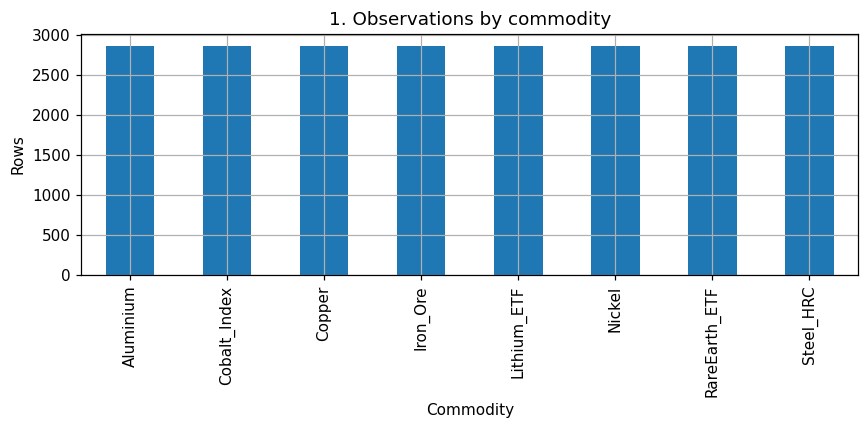

In [2]:
df["commodity"].value_counts().plot(kind="bar"); finish("1. Observations by commodity", "Commodity", "Rows")

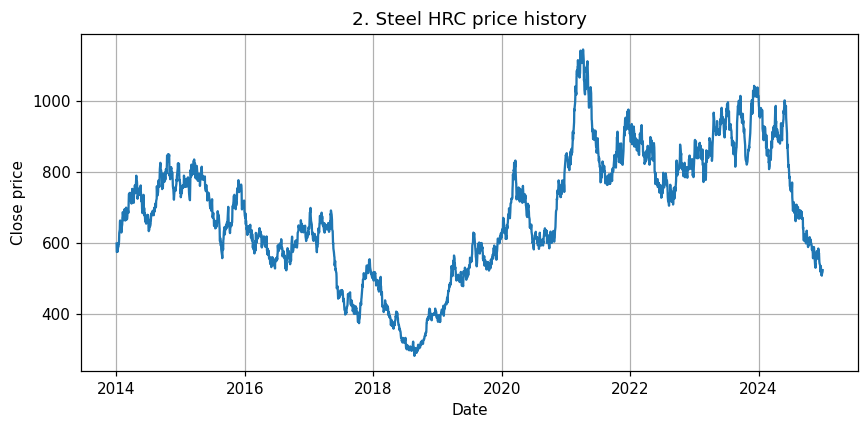

In [3]:
g = df[df["commodity"] == "Steel_HRC"].sort_values("date"); plt.plot(g["date"], g["close"]); finish("2. Steel HRC price history", "Date", "Close price")

/usr/lib/python3.13/copy.py:254: FutureWarning: Period with BDay freq is deprecated and will be removed in a future version. Use a DatetimeIndex with BDay freq instead.
  y = func(*args)


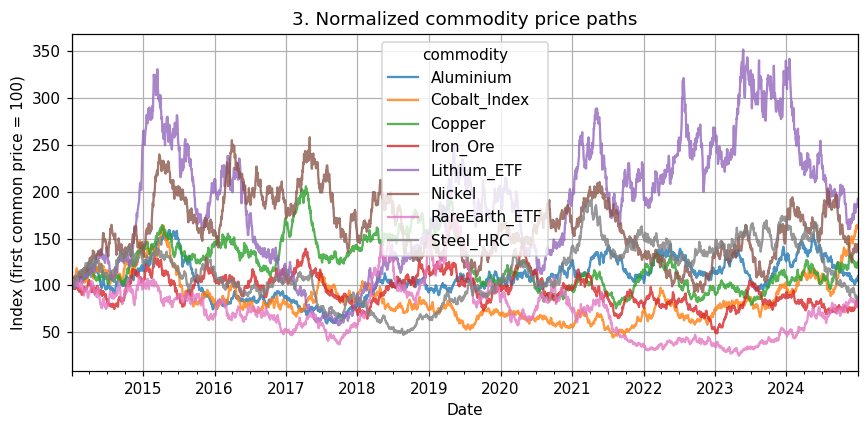

In [4]:
pivot = df.pivot(index="date", columns="commodity", values="close"); normalized = pivot / pivot.bfill().iloc[0] * 100; normalized.plot(ax=plt.gca(), alpha=.8); finish("3. Normalized commodity price paths", "Date", "Index (first common price = 100)")

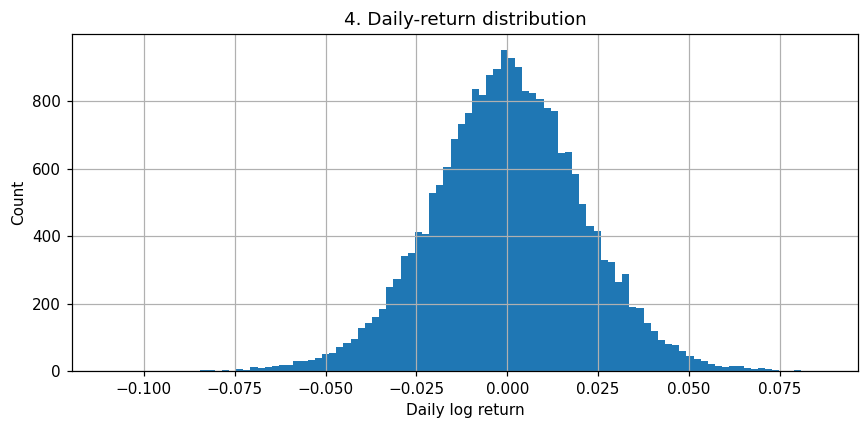

In [5]:
df["daily_return"].dropna().hist(bins=100); finish("4. Daily-return distribution", "Daily log return", "Count")

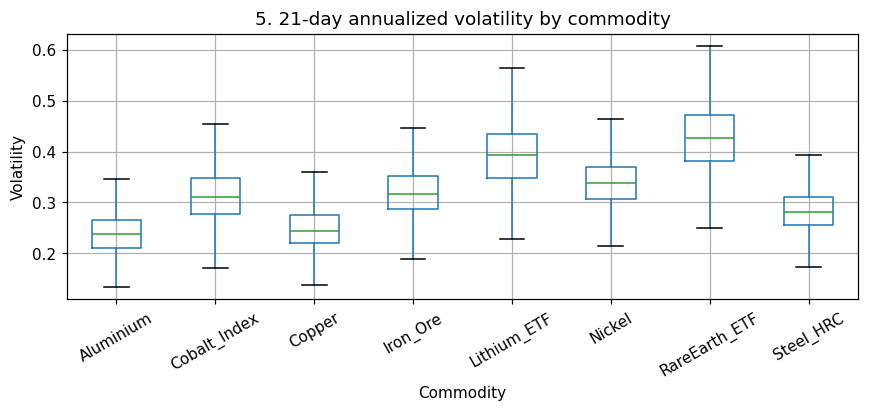

In [6]:
df.boxplot(column="volatility_21d_ann", by="commodity", grid=True, showfliers=False); plt.xticks(rotation=30); plt.suptitle(""); finish("5. 21-day annualized volatility by commodity", "Commodity", "Volatility")

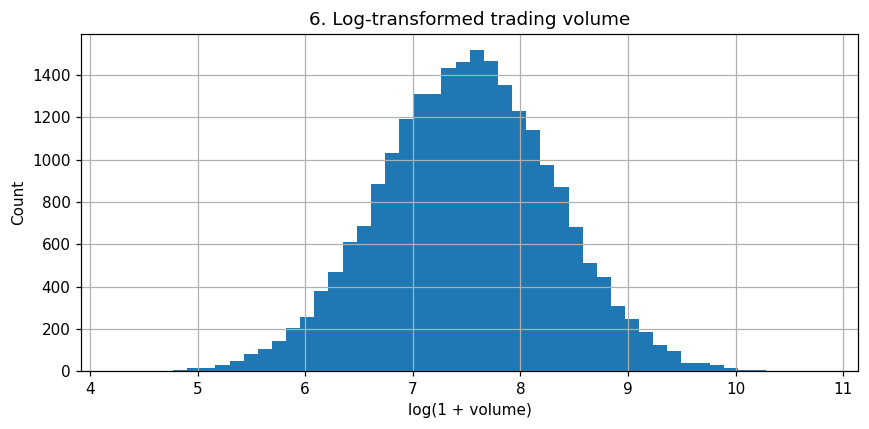

In [7]:
np.log1p(df["volume"].clip(lower=0)).hist(bins=50); finish("6. Log-transformed trading volume", "log(1 + volume)", "Count")

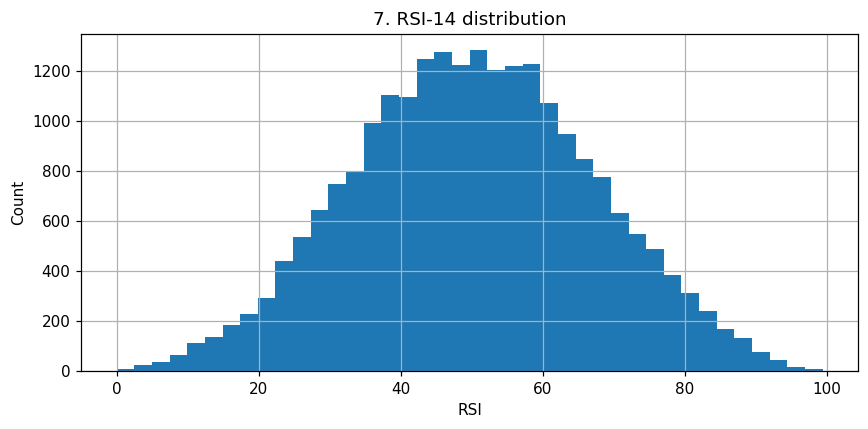

In [8]:
df["rsi_14"].dropna().hist(bins=40); finish("7. RSI-14 distribution", "RSI", "Count")

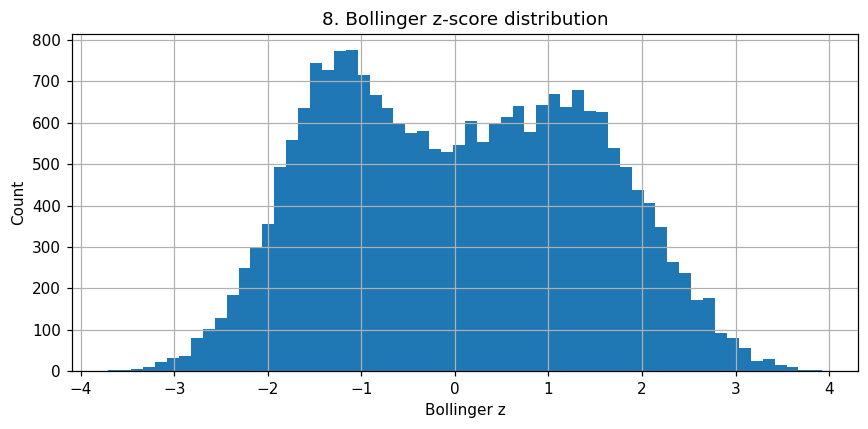

In [9]:
df["bollinger_z"].dropna().hist(bins=60); finish("8. Bollinger z-score distribution", "Bollinger z", "Count")

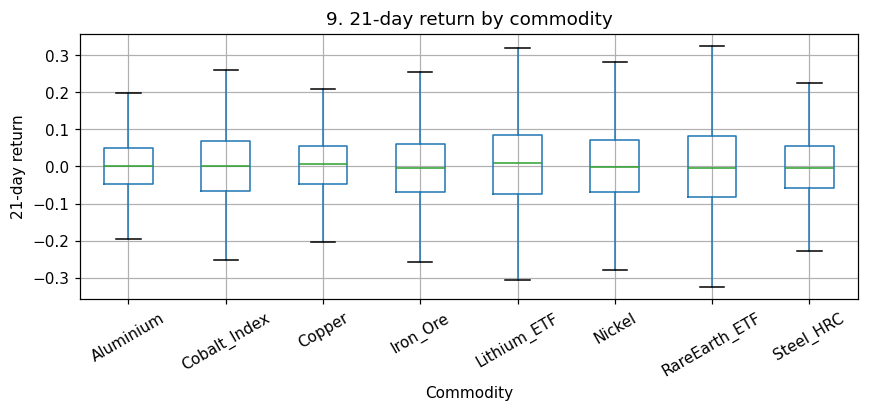

In [10]:
ret = df.dropna(subset=["return_21d"]); ret.boxplot(column="return_21d", by="commodity", grid=True, showfliers=False); plt.xticks(rotation=30); plt.suptitle(""); finish("9. 21-day return by commodity", "Commodity", "21-day return")

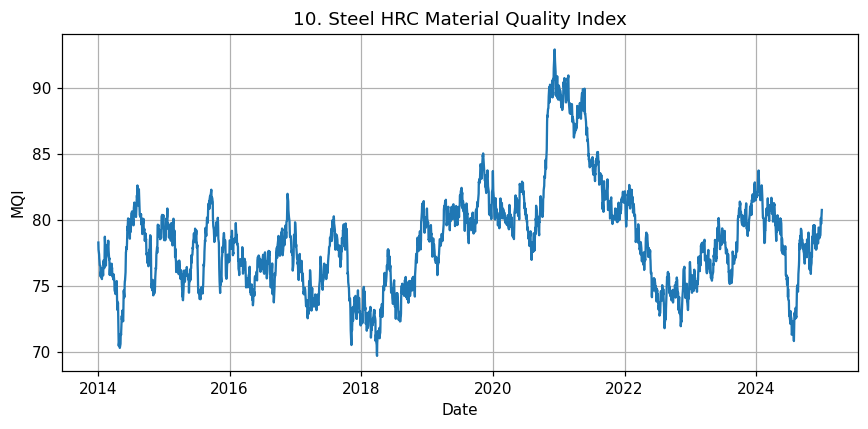

In [11]:
g = df[df["commodity"] == "Steel_HRC"].sort_values("date"); plt.plot(g["date"], g["mqi"]); finish("10. Steel HRC Material Quality Index", "Date", "MQI")

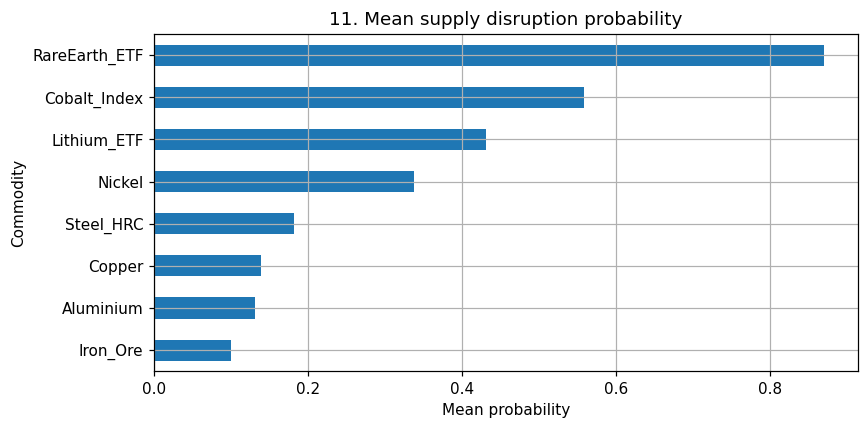

In [12]:
df.groupby("commodity")["supply_disruption_prob"].mean().sort_values().plot(kind="barh"); finish("11. Mean supply disruption probability", "Mean probability", "Commodity")

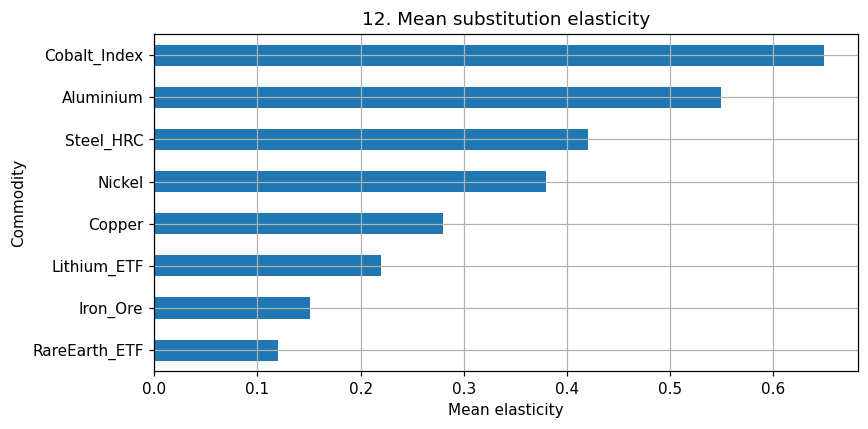

In [13]:
df.groupby("commodity")["substitution_elasticity"].mean().sort_values().plot(kind="barh"); finish("12. Mean substitution elasticity", "Mean elasticity", "Commodity")

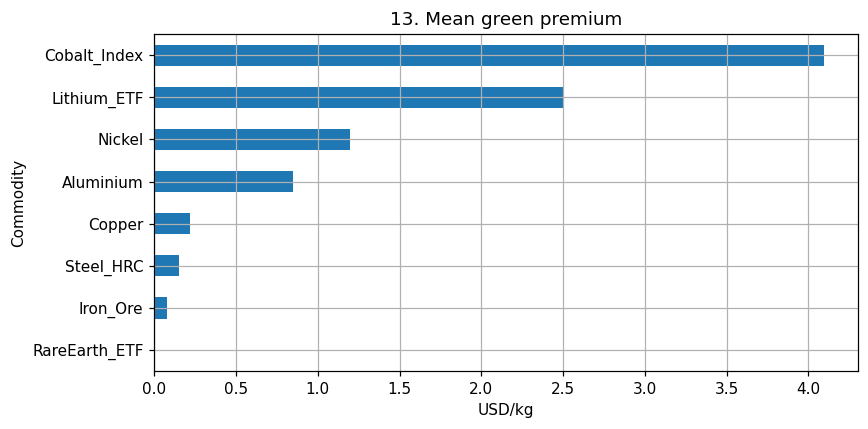

In [14]:
df.groupby("commodity")["green_premium_per_kg"].mean().sort_values().plot(kind="barh"); finish("13. Mean green premium", "USD/kg", "Commodity")

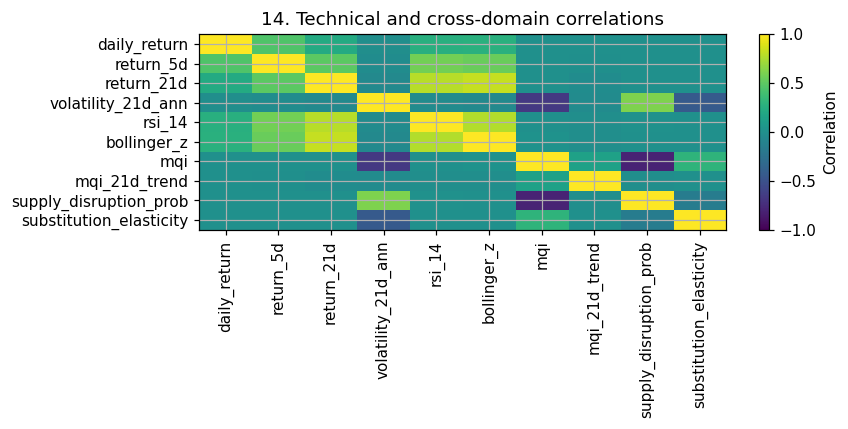

In [15]:
cols = ["daily_return", "return_5d", "return_21d", "volatility_21d_ann", "rsi_14", "bollinger_z", "mqi", "mqi_21d_trend", "supply_disruption_prob", "substitution_elasticity"]; c = df[cols].corr(); plt.imshow(c, aspect="auto", vmin=-1, vmax=1); plt.xticks(range(len(cols)), cols, rotation=90); plt.yticks(range(len(cols)), cols); plt.colorbar(label="Correlation"); finish("14. Technical and cross-domain correlations")

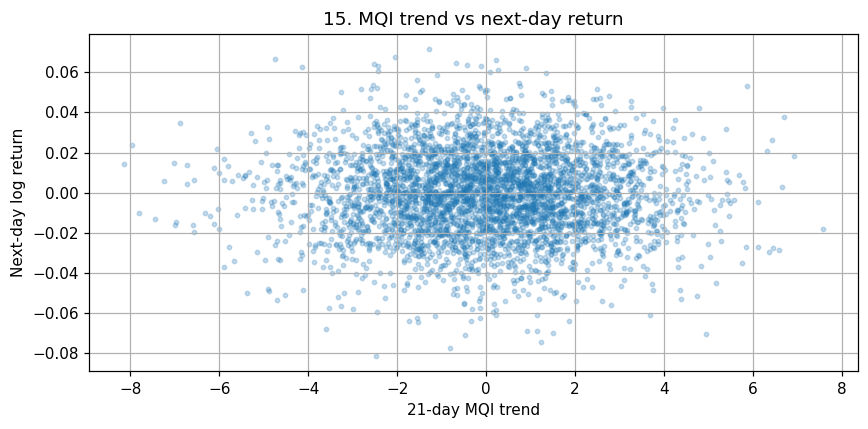

In [16]:
sample = df.dropna(subset=["mqi_21d_trend", "next_day_return"]).sample(min(4000, df["mqi_21d_trend"].notna().sum()), random_state=42); plt.scatter(sample["mqi_21d_trend"], sample["next_day_return"], alpha=.25, s=8); finish("15. MQI trend vs next-day return", "21-day MQI trend", "Next-day log return")

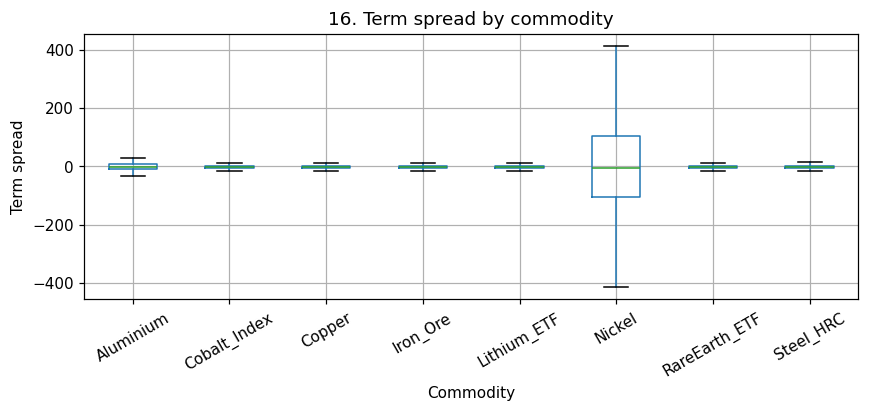

In [17]:
df.boxplot(column="term_spread", by="commodity", grid=True, showfliers=False); plt.xticks(rotation=30); plt.suptitle(""); finish("16. Term spread by commodity", "Commodity", "Term spread")